# Exercício 1

Considere a variável aleatória contínua $X$ com densidade

$$
f(x)=20x(1-x)^3, \qquad 0\leq x\leq 1,
$$

e $f(x)=0$ fora do intervalo $[0,1]$.

1. Utilizando o método de Aceitação-Rejeição (AR), gere uma amostra i.i.d. de tamanho $n$ da distribuição com densidade $f$. Utilize como distribuição proposta uma distribuição Uniforme em $[0,1]$.

   Para determinar a constante $M$ do método de Aceitação-Rejeição, aproxime numericamente o máximo de $f$ no intervalo $[0,1]$. Para isso, construa uma malha suficientemente fina utilizando `np.linspace`, avalie a função $f$ nos pontos dessa malha e utilize `np.max` para obter uma aproximação de

$$
M = \max_{0\leq x\leq 1} f(x).
$$

2. Faça um gráfico contendo a densidade teórica $f(x)$ e o histograma normalizado da amostra gerada. Compare visualmente a distribuição da amostra com a densidade teórica.

3. Para cada observação gerada, registre o número de tentativas necessárias até ocorrer a primeira aceitação.

   a. Determine teoricamente a probabilidade de aceitação do método AR.

   b. Determine o número esperado de tentativas até a primeira aceitação.

   c. Compare a média empírica do número de tentativas com o valor esperado teoricamente.

   d. Determine a distribuição teórica do número de tentativas até a primeira aceitação e compare-a com a distribuição empírica obtida na simulação.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
def f(x):
  return 20*x*((1-x)**3)

In [3]:
amostra_tentativas = []

In [4]:
x = np.linspace(0,1,1000)

c = np.max(f(x))+0.1
amostra = []
N = 1000
for i in range(N):
  tentativas = 1
  y = np.random.uniform()
  U = np.random.uniform()
  while U > f(y)/c:
    tentativas += 1
    y = np.random.uniform()
    U = np.random.uniform()
  X = y
  amostra.append(X)
  amostra_tentativas.append(tentativas)

(array([0.80169951, 1.78288399, 1.99826595, 1.86664365, 1.9504033 ,
        1.2444291 , 1.16066945, 0.64614588, 0.35896993, 0.15555364]),
 array([0.00251628, 0.08608874, 0.1696612 , 0.25323366, 0.33680612,
        0.42037858, 0.50395104, 0.5875235 , 0.67109595, 0.75466841,
        0.83824087]),
 <BarContainer object of 10 artists>)

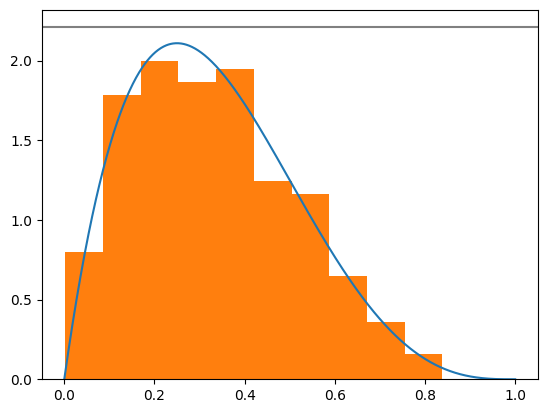

In [5]:
plt.plot(x,f(x))
plt.axhline(y=c, c = "gray")

plt.hist(amostra,density = True, bins = 10)

In [6]:
print(np.mean(amostra_tentativas))
print(c)

2.255
2.209373591560076


Text(0.5, 1.0, 'Distribuição Numpy')

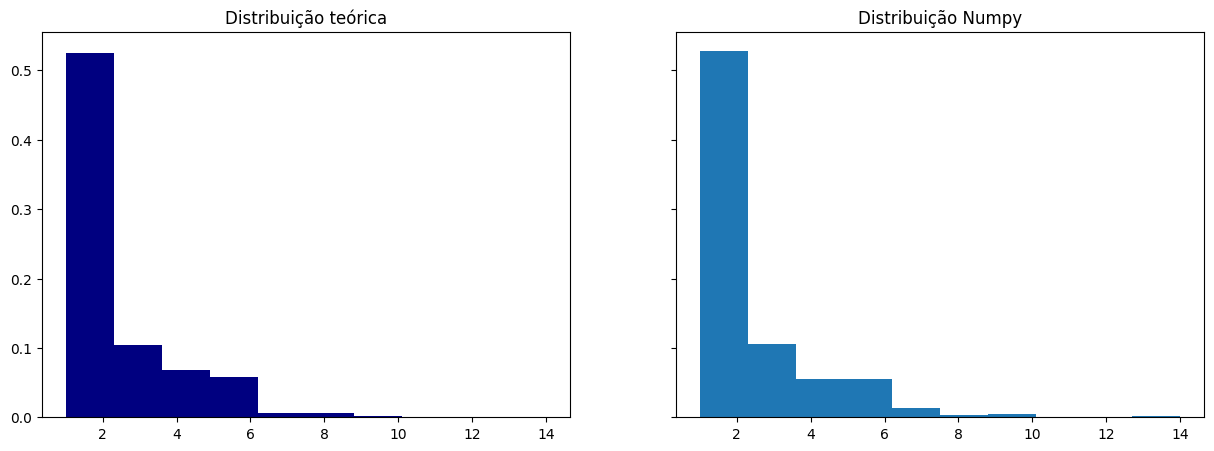

In [25]:
fig, axs = plt.subplots(1, 2, figsize = (15,5), sharey=True)
axs[0].hist(amostra_tentativas, color = "navy", density = True)
axs[0].set_title("Distribuição teórica")
axs[1].hist(np.random.geometric(1/c, 1000), density = True)
axs[1].set_title("Distribuição Numpy")